# ML-10 — Content Action Playbook

This playbook turns the Week-6, client-held-out score into a **human-reviewed research queue**, not a production system. It ranks items for triage, gives observable reason codes, and records the limits beside the proposed actions. The local snapshot and label are the same as Week 6; they are not the separate gated March warehouse experiment.

The current evidence is directional: on one client-held-out split, ROC-AUC was 0.562 and precision@50 was 0.840 against a test base rate of 0.517. The rolling 90-day feature window may overlap the trend-derived label window. The queue is therefore for discussion and review, not proof of future performance or refresh impact.

## 1. Ranked actions + reason codes

The model score orders a bounded queue; it is not a probability of recovery or business value. Reason codes are transparent observations used to explain a proposed review. Multiple codes may apply; the primary archetype selects the first relevant review action. Ranking is restricted to the Week-6 held-out clients so the paper queue reflects out-of-sample scores. Pseudonymous IDs are written only to the git-ignored CSV and are never displayed in this notebook.

In [1]:
from pathlib import Path

import json
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "content_refresh_anonymized.csv").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not locate the bundled anonymized CSV from the notebook directory.")
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "content_refresh_anonymized.csv"
data = pd.read_csv(DATA_PATH)

required = {
    "content_id", "client_id", "trend_direction", "trend_pct", "impressions_90d",
    "clicks_90d", "sessions_90d", "avg_position", "ctr", "engagement_rate",
    "scroll_rate", "content_age_days", "days_since_last_update", "word_count",
}
missing = sorted(required - set(data.columns))
if missing:
    raise ValueError(f"The bundled dataset is missing required playbook columns: {missing}")

numeric_columns = [
    "impressions_90d", "clicks_90d", "sessions_90d", "avg_position", "ctr",
    "engagement_rate", "scroll_rate", "content_age_days", "days_since_last_update",
    "word_count", "trend_pct",
]
for column in numeric_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
data["trend_direction"] = data["trend_direction"].fillna("unknown").astype(str).str.lower()
data = data.loc[(data["impressions_90d"] > 0) & (data["content_age_days"] >= 90)].copy()
data = data.drop_duplicates(subset=["content_id"]).reset_index(drop=True)
data["target"] = data["trend_direction"].eq("down").astype(int)

FEATURE_COLUMNS = ["impressions_90d", "clicks_90d", "avg_position", "days_with_impressions", "ctr"]
if "days_with_impressions" not in data.columns:
    raise ValueError("Required model feature 'days_with_impressions' is missing.")
X = data[FEATURE_COLUMNS].copy()
y = data["target"]
groups = data["client_id"].fillna("unknown").astype(str)
if y.nunique() != 2 or groups.nunique() < 5:
    raise ValueError("The eligible data must have both target classes and at least five client groups.")

train_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(X, y, groups=groups)
)
train_clients = set(groups.iloc[train_idx])
test_clients = set(groups.iloc[test_idx])
if train_clients.intersection(test_clients):
    raise AssertionError("Client IDs crossed the grouped train/test boundary.")
if y.iloc[train_idx].nunique() != 2 or y.iloc[test_idx].nunique() != 2:
    raise ValueError("Both target classes must be present in the grouped train and test splits.")

model = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
)
model.fit(X.iloc[train_idx], y.iloc[train_idx])
test_scores = model.predict_proba(X.iloc[test_idx])[:, 1]
test_labels = y.iloc[test_idx].to_numpy()

def precision_at_k(labels, scores, k):
    labels = np.asarray(labels)
    scores = np.asarray(scores)
    top = np.argsort(-scores, kind="stable")[: min(k, len(labels))]
    return float(labels[top].mean())

holdout_metrics = {
    "eligible_rows": int(len(data)),
    "train_rows": int(len(train_idx)),
    "test_rows": int(len(test_idx)),
    "train_clients": int(len(train_clients)),
    "test_clients": int(len(test_clients)),
    "client_overlap": int(len(train_clients.intersection(test_clients))),
    "base_rate": float(test_labels.mean()),
    "roc_auc": float(roc_auc_score(test_labels, test_scores)),
    "average_precision": float(average_precision_score(test_labels, test_scores)),
    "precision_at_50": precision_at_k(test_labels, test_scores, 50),
    "precision_at_100": precision_at_k(test_labels, test_scores, 100),
}
display(pd.DataFrame([holdout_metrics]).round(3))

,eligible_rows,train_rows,test_rows,train_clients,test_clients,client_overlap,base_rate,roc_auc,average_precision,precision_at_50,precision_at_100
0,30000,22885,7115,24,8,0,0.517,0.562,0.575,0.84,0.78


### Archetype → action mapping

| Primary archetype / reason code | Proposed review action | Evidence a reviewer checks |
|---|---|---|
| `visible_low_ctr` | Review title/snippet and query intent; test a change only through an approved editorial process | Verify impressions, position, actual SERP context, intent match, and CTR units (percent ×100) |
| `observed_decline` | Diagnose what changed before considering a refresh | Compare the two 30-day windows, seasonality, tracking changes, and current demand |
| `aging_visible` | Schedule a freshness/content review | Confirm last-update metadata and whether information is actually stale |
| `thin_visible` | Review coverage and missing sections | Read the page and check whether useful subtopics are genuinely absent; do not pad word count |
| `engagement_check` | Review readability and page experience | Verify analytics coverage, device/context, and whether engagement rates are interpretable |
| `general_review` | Monitor or manually triage; no specific edit is implied | Check context and data quality before action |

Reason codes may overlap. The primary action is chosen in the order above; all applicable codes remain visible in the queue. This order is a triage convention, not a learned causal hierarchy.

In [2]:
scored = data.iloc[test_idx].copy().reset_index(drop=True)
scored["review_score"] = test_scores

def classify_archetype(row):
    impressions = row["impressions_90d"]
    position = row["avg_position"]
    codes = []
    if impressions >= 500 and pd.notna(position) and 0 < position <= 20 and pd.notna(row["ctr"]) and row["ctr"] < 0.5:
        codes.append("visible_low_ctr")
    if row["trend_direction"] == "down" and impressions >= 100:
        codes.append("observed_decline")
    if pd.notna(row["days_since_last_update"]) and row["days_since_last_update"] >= 180 and impressions >= 500:
        codes.append("aging_visible")
    if pd.notna(row["word_count"]) and 0 < row["word_count"] < 1200 and impressions >= 250:
        codes.append("thin_visible")
    engagement_weak = (
        (pd.notna(row["engagement_rate"]) and 0 < row["engagement_rate"] < 30)
        or (pd.notna(row["scroll_rate"]) and 0 < row["scroll_rate"] < 30)
    )
    if pd.notna(row["sessions_90d"]) and row["sessions_90d"] >= 30 and engagement_weak:
        codes.append("engagement_check")
    if not codes:
        codes.append("general_review")
    primary = codes[0]
    action = {
        "visible_low_ctr": "review_title_snippet_and_intent",
        "observed_decline": "diagnose_change_before_refresh",
        "aging_visible": "schedule_freshness_review",
        "thin_visible": "review_topic_coverage",
        "engagement_check": "review_readability_and_experience",
        "general_review": "monitor_or_manual_triage",
    }[primary]
    return pd.Series({"primary_archetype": primary, "reason_codes": "|".join(codes), "proposed_action": action})

scored = pd.concat([scored, scored.apply(classify_archetype, axis=1)], axis=1)
scored = scored.sort_values(["review_score", "impressions_90d"], ascending=[False, False], kind="stable").reset_index(drop=True)
scored.insert(0, "review_rank", np.arange(1, len(scored) + 1))
QUEUE_SIZE = min(500, len(scored))
ranked_queue = scored.head(QUEUE_SIZE).copy()

action_mix = (
    ranked_queue["primary_archetype"].value_counts()
    .rename_axis("primary_archetype").rename("items").reset_index()
)
display(action_mix)
if int(action_mix["items"].sum()) != len(ranked_queue):
    raise ValueError("The aggregate action counts must cover the complete ranked review queue.")
print("The ranked queue is written to the ignored local CSV; row-level queue records are not rendered in this public notebook.")

,primary_archetype,items
0,visible_low_ctr,487
1,observed_decline,7
2,general_review,6


The ranked queue is written to the ignored local CSV; row-level queue records are not rendered in this public notebook.


## 2. Intended use and limits

**Intended use:** a content editor or analyst can use a small, ranked batch to decide what deserves an initial manual look. Reason codes point to checks, not guaranteed fixes. The model score is an ordering aid for observed decline-label agreement on the held-out snapshot; it does not estimate recoverable traffic, editorial impact, or financial return.

**Decay / refresh insight:** the March 2026 paper reports the 31–90-day freshness band as the strongest stable growth-to-decline band (7.88:1), while warning that the 361+ day ratio is sparse (one declining page). It also reports higher health/impressions among recently refreshed mature pages, but refresh selection is observational: pages chosen for refresh may already differ from untouched pages. Treat age/freshness as a reason to inspect and verify, not a refresh schedule proven to cause gains. Aged pages with verified demand may merit a review before an older page is assumed to be a good candidate.

**Limits:** one grouped split, 32 pseudonymous clients in the starter snapshot, a threshold-derived `down` label, a modest ROC-AUC, and overlapping rolling windows. There is no prospective validation, treatment comparison, quantified editing cost, or measured revenue outcome. The gated Week-5 March data is not the local input to this queue. Any current use would require a fresh approved extract and revalidation.

In [3]:
intended_use = pd.DataFrame([
    {"question": "Who uses it?", "answer": "An editor or analyst planning a limited manual review batch."},
    {"question": "What does the score mean?", "answer": "A ranking score for agreement with the observed decline proxy in one grouped holdout; not recovery probability."},
    {"question": "What evidence supports ordering?", "answer": f"Held-out ROC-AUC {holdout_metrics['roc_auc']:.3f}; precision@50 {holdout_metrics['precision_at_50']:.3f} vs base rate {holdout_metrics['base_rate']:.3f}."},
    {"question": "What is not established?", "answer": "Future-month performance, refresh impact, causal benefit, or monetary value."},
    {"question": "Freshness interpretation", "answer": "A review cue only; paper findings are observational and the sparse 361+ band is not a reliable multiplier."},
])
display(intended_use)

,question,answer
0,Who uses it?,An editor or analyst planning a limited manual...
1,What does the score mean?,A ranking score for agreement with the observe...
2,What evidence supports ordering?,Held-out ROC-AUC 0.562; precision@50 0.840 vs ...
3,What is not established?,"Future-month performance, refresh impact, caus..."
4,Freshness interpretation,A review cue only; paper findings are observat...


## 3. Human review + the no-go list

**Before any action:** confirm the page and current business context in approved internal tools; verify the metric window, sample volume, position, CTR units, analytics availability, and last-update record; inspect the actual search result and intended audience; check for seasonality, tracking changes, and current content accuracy; record the reviewer’s decision and reason. A reason code alone is not enough to edit.

**Do not automate:** publishing or rewriting content, changing titles/meta descriptions, deleting or redirecting pages, changing legal/medical/financial or other high-stakes statements, client prioritization, budget allocation, promises of traffic recovery, or a decision to refresh solely because a page is old or has a high score. A qualified human owns every decision and final edit.

**Cost/value thinking:** choose a queue size that fits real reviewer capacity. As an explicit planning example—not a measured cost—an initial 5–10 minute triage of 50 items uses about 4.2–8.3 staff-hours; deeper edits are additional. Compare that effort with a human-recorded outcome and an appropriate later measurement window before claiming value. Do not translate precision@K into clicks, revenue, or ROI.

In [4]:
review_steps = pd.DataFrame([
    (1, "Confirm the page and the approved data are current; IDs in the queue are pseudonymous lookup keys only."),
    (2, "Verify the metric window, impressions, position, CTR percent scale, and data coverage."),
    (3, "Inspect actual query intent/SERP context, seasonality, tracking changes, accuracy, and editorial constraints."),
    (4, "Choose review, monitor, or no action; document why. A model rank is not an edit instruction."),
    (5, "If edited, record the human decision and define a later measurement window; do not infer causality from before/after alone."),
], columns=["step", "human review rule"])
no_go = pd.DataFrame([
    "Auto-publish, rewrite, or directly change titles/snippets",
    "Delete, redirect, or deindex pages from score alone",
    "Automate high-stakes claims or bypass legal/editorial review",
    "Allocate client budgets or promise traffic/revenue recovery",
    "Use age, a label, a reason code, or score as a sufficient action condition",
], columns=["must not be automated"])
display(review_steps)
display(no_go)

triage_minutes = (5, 10)
batch_size = 50
hours = [batch_size * minutes / 60 for minutes in triage_minutes]
print(f"Illustrative only: {batch_size} items × {triage_minutes[0]}–{triage_minutes[1]} minutes = {hours[0]:.1f}–{hours[1]:.1f} reviewer-hours; this is a planning assumption, not a measured cost.")

,step,human review rule
0,1,Confirm the page and the approved data are cur...
1,2,"Verify the metric window, impressions, positio..."
2,3,"Inspect actual query intent/SERP context, seas..."
3,4,"Choose review, monitor, or no action; document..."
4,5,"If edited, record the human decision and defin..."


,must not be automated
0,"Auto-publish, rewrite, or directly change titl..."
1,"Delete, redirect, or deindex pages from score ..."
2,Automate high-stakes claims or bypass legal/ed...
3,Allocate client budgets or promise traffic/rev...
4,"Use age, a label, a reason code, or score as a..."


Illustrative only: 50 items × 5–10 minutes = 4.2–8.3 reviewer-hours; this is a planning assumption, not a measured cost.


## 4. Monitoring / retrain triggers

For a non-production pilot, review a fixed-size batch monthly and keep a human decision log. Recheck data coverage, label prevalence, ranking metrics against the base rate, and reason-code mix. These are proposed guardrails, not established operating thresholds. Pause use and investigate on a schema/window change, a broken feature, unusual missingness, or a repeated material drop in held-out performance. Retraining is not an automatic response: first verify the label, time alignment, client mix, and whether a fresh time-aware or group-held-out evaluation is possible. Never reuse future outcomes as features.

In [5]:
monitoring_triggers = pd.DataFrame([
    {"check": "Schema / metric window", "cadence": "Before each refresh", "investigate when": "Any field definition, source, or observation window changes; pause queue use until revalidated."},
    {"check": "Coverage / missingness", "cadence": "Each monthly batch", "investigate when": "A key feature's missing share shifts by more than 10 percentage points from this audit's measured baseline."},
    {"check": "Label prevalence and client mix", "cadence": "Each monthly batch", "investigate when": "Decline-label base rate shifts by more than 5 percentage points, or held-out client composition differs materially."},
    {"check": "Ranking quality", "cadence": "When later labels mature", "investigate when": "ROC-AUC or precision@50 drops by more than 0.05 absolute from the measured grouped-holdout reference, across two reviewed batches."},
    {"check": "Human decision log", "cadence": "Each reviewed batch", "investigate when": "Reason codes repeatedly do not match reviewer findings, or reviewers routinely reject the proposed action."},
    {"check": "Retrain gate", "cadence": "Only after investigation", "investigate when": "A corrected label/window and fresh group/time-aware validation show stable out-of-sample utility; otherwise retain, revise, or retire the model."},
])
display(monitoring_triggers)

,check,cadence,investigate when
0,Schema / metric window,Before each refresh,"Any field definition, source, or observation w..."
1,Coverage / missingness,Each monthly batch,A key feature's missing share shifts by more t...
2,Label prevalence and client mix,Each monthly batch,Decline-label base rate shifts by more than 5 ...
3,Ranking quality,When later labels mature,ROC-AUC or precision@50 drops by more than 0.0...
4,Human decision log,Each reviewed batch,Reason codes repeatedly do not match reviewer ...
5,Retrain gate,Only after investigation,A corrected label/window and fresh group/time-...


## 5. Exports for the paper

The ranked queue is regenerated under `work/outputs/` and remains untracked by the repo’s CSV guard. The aggregate metrics JSON and action-mix figure are paper receipts and are committed. The queue CSV contains pseudonymous lookup keys for local review, but no target label; it must not be treated as a public dataset. The chart contains only aggregated counts.

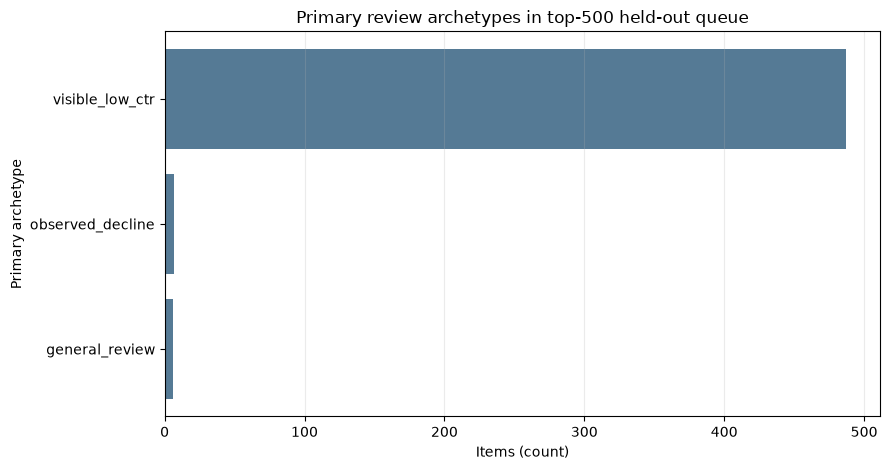

Queue CSV (git-ignored): work\outputs\w07_ranked_action_queue.csv
Aggregate metrics JSON: work\outputs\w07_playbook_metrics.json
Paper figure: work\figures\w07_action_mix.png
Queue columns include IDs only for local lookup; notebook display omits IDs and target labels.


In [6]:
import matplotlib.pyplot as plt

OUTPUT_DIR = ROOT / "work" / "outputs"
FIGURE_DIR = ROOT / "work" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

queue_columns = [
    "review_rank", "content_id", "client_id", "review_score", "primary_archetype",
    "reason_codes", "proposed_action", "impressions_90d", "clicks_90d", "sessions_90d",
    "avg_position", "ctr", "days_since_last_update", "content_age_days", "word_count",
]
queue_path = OUTPUT_DIR / "w07_ranked_action_queue.csv"
ranked_queue[queue_columns].to_csv(queue_path, index=False)

metrics_payload = {
    "notebook": "work/notebooks/w07_action_playbook.ipynb",
    "source": "bundled anonymized starter snapshot; eligible items require impressions_90d > 0 and content_age_days >= 90",
    "label": "trend_direction == down (threshold-derived observed decline proxy)",
    "model": "median-imputed, standardized, class-balanced logistic regression",
    "split": "one GroupShuffleSplit by pseudonymous client_id; test_size=0.25; random_state=42",
    "features": FEATURE_COLUMNS,
    "metric_scope": "held-out clients only; rolling feature window may overlap label window; not future-period or causal evidence",
    "queue_rows": int(len(ranked_queue)),
    "queue_scope": "top-scored held-out rows; model score ranks observed decline-label agreement, not refresh benefit",
    "metrics": holdout_metrics,
    "primary_archetype_counts_in_queue": {str(key): int(value) for key, value in ranked_queue["primary_archetype"].value_counts().items()},
    "reason_codes": "transparent review cues; one primary archetype and pipe-delimited applicable reasons",
    "privacy": "CSV contains pseudonymous lookup IDs and is git-ignored; JSON and figure contain aggregate results only",
    "human_review_required": True,
    "production_ready": False,
}
metrics_path = OUTPUT_DIR / "w07_playbook_metrics.json"
metrics_path.write_text(json.dumps(metrics_payload, indent=2, sort_keys=True) + "\n", encoding="utf-8")

figure_path = FIGURE_DIR / "w07_action_mix.png"
plot_data = action_mix.sort_values("items", ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(plot_data["primary_archetype"], plot_data["items"], color="#557A95")
ax.set_title(f"Primary review archetypes in top-{len(ranked_queue)} held-out queue")
ax.set_xlabel("Items (count)")
ax.set_ylabel("Primary archetype")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

if not queue_path.is_file() or not metrics_path.is_file() or not figure_path.is_file():
    raise FileNotFoundError("One or more requested paper exports were not written.")
print(f"Queue CSV (git-ignored): {queue_path.relative_to(ROOT)}")
print(f"Aggregate metrics JSON: {metrics_path.relative_to(ROOT)}")
print(f"Paper figure: {figure_path.relative_to(ROOT)}")
print(f"Queue columns include IDs only for local lookup; notebook display omits IDs and target labels.")

## Self-check

- [x] Ranked actions have reason codes and an explicit archetype → action mapping.
- [x] Freshness/decay is framed as an observational review cue, not a causal promise.
- [x] Intended use, limits, human review, no-go automation cases, cost/value thinking, and monitoring/retrain triggers are stated.
- [x] Queue CSV is regenerated under `work/outputs/` and git-ignored; aggregate metrics JSON and figure are paper-ready exports.
- [x] Notebook runs top to bottom without errors; no IDs or private queries are displayed.
- [x] Commit the executed notebook, aggregate metrics JSON, and figure; submit the repository URL on the card.